In [1]:
!pip -q install xgboost shap imbalanced-learn joblib

In [3]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Suppress only specific known warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Machine Learning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_val_score
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    brier_score_loss
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN, SMOTETomek

import shap

MODEL_VERSION = "1.0.0"

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
try:
    from google.colab import files
    uploaded = files.upload()
    CSV_FILE = list(uploaded.keys())[0]
    print(f"Uploaded: {CSV_FILE}")
except (ImportError, Exception):
    CSV_FILE = "fraud_oracle.csv"
    print(f"Running locally. Using: {CSV_FILE}")

Saving fraud_oracle.csv to fraud_oracle.csv
Uploaded: fraud_oracle.csv


In [5]:
df = pd.read_csv(CSV_FILE)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (15420, 33)


In [6]:
df.head(10)

,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision
5,Oct,4,Friday,Honda,Urban,Wednesday,Nov,1,Male,Single,...,5 years,21 to 25,No,No,External,3 to 5,no change,1 vehicle,1994,Collision
6,Feb,1,Saturday,Honda,Urban,Monday,Feb,3,Male,Married,...,7 years,36 to 40,No,No,External,1 to 2,no change,1 vehicle,1994,Collision
7,Nov,1,Friday,Honda,Urban,Tuesday,Mar,4,Male,Single,...,new,16 to 17,No,No,External,none,no change,1 vehicle,1994,Collision
8,Dec,4,Saturday,Honda,Urban,Wednesday,Dec,5,Male,Single,...,6 years,31 to 35,No,Yes,External,3 to 5,no change,1 vehicle,1994,Collision
9,Apr,3,Tuesday,Ford,Urban,Wednesday,Apr,3,Male,Married,...,more than 7,36 to 40,No,No,External,3 to 5,no change,1 vehicle,1994,All Perils


In [7]:
df.tail(10)

,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
15410,Nov,3,Sunday,Dodge,Urban,Tuesday,Nov,4,Female,Single,...,7 years,31 to 35,No,No,External,more than 5,no change,1 vehicle,1996,Collision
15411,Nov,4,Tuesday,Honda,Rural,Wednesday,Nov,5,Male,Married,...,7 years,36 to 40,No,No,External,none,no change,1 vehicle,1996,All Perils
15412,Nov,4,Tuesday,Pontiac,Urban,Wednesday,Nov,4,Female,Single,...,5 years,31 to 35,No,No,External,more than 5,no change,1 vehicle,1996,Liability
15413,Nov,4,Thursday,Mazda,Urban,Monday,Nov,4,Male,Married,...,7 years,36 to 40,Yes,No,External,1 to 2,no change,1 vehicle,1996,Liability
15414,Nov,4,Friday,Chevrolet,Urban,Monday,Nov,4,Male,Single,...,7 years,51 to 65,No,No,External,1 to 2,4 to 8 years,2 vehicles,1996,Collision
15415,Nov,4,Friday,Toyota,Urban,Tuesday,Nov,5,Male,Married,...,6 years,31 to 35,No,No,External,none,no change,1 vehicle,1996,Collision
15416,Nov,5,Thursday,Pontiac,Urban,Friday,Dec,1,Male,Married,...,6 years,31 to 35,No,No,External,more than 5,no change,3 to 4,1996,Liability
15417,Nov,5,Thursday,Toyota,Rural,Friday,Dec,1,Male,Single,...,5 years,26 to 30,No,No,External,1 to 2,no change,1 vehicle,1996,Collision
15418,Dec,1,Monday,Toyota,Urban,Thursday,Dec,2,Female,Married,...,2 years,31 to 35,No,No,External,more than 5,no change,1 vehicle,1996,All Perils
15419,Dec,2,Wednesday,Toyota,Urban,Thursday,Dec,3,Male,Single,...,5 years,26 to 30,No,No,External,1 to 2,no change,1 vehicle,1996,Collision


In [8]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 15420
Columns: 33


In [9]:
print("Dataset Columns:\n")

for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

Dataset Columns:

1. Month
2. WeekOfMonth
3. DayOfWeek
4. Make
5. AccidentArea
6. DayOfWeekClaimed
7. MonthClaimed
8. WeekOfMonthClaimed
9. Sex
10. MaritalStatus
11. Age
12. Fault
13. PolicyType
14. VehicleCategory
15. VehiclePrice
16. FraudFound_P
17. PolicyNumber
18. RepNumber
19. Deductible
20. DriverRating
21. Days_Policy_Accident
22. Days_Policy_Claim
23. PastNumberOfClaims
24. AgeOfVehicle
25. AgeOfPolicyHolder
26. PoliceReportFiled
27. WitnessPresent
28. AgentType
29. NumberOfSuppliments
30. AddressChange_Claim
31. NumberOfCars
32. Year
33. BasePolicy


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-null  object
 4   AccidentArea          15420 non-null  object
 5   DayOfWeekClaimed      15420 non-null  object
 6   MonthClaimed          15420 non-null  object
 7   WeekOfMonthClaimed    15420 non-null  int64 
 8   Sex                   15420 non-null  object
 9   MaritalStatus         15420 non-null  object
 10  Age                   15420 non-null  int64 
 11  Fault                 15420 non-null  object
 12  PolicyType            15420 non-null  object
 13  VehicleCategory       15420 non-null  object
 14  VehiclePrice          15420 non-null  object
 15  FraudFound_P          15420 non-null

In [11]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Month,15420,12,Jan,1411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WeekOfMonth,15420.0,NaN,NaN,NaN,2.788586,1.287585,1.0,2.0,3.0,4.0,5.0
DayOfWeek,15420,7,Monday,2616,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Make,15420,19,Pontiac,3837,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AccidentArea,15420,2,Urban,13822,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DayOfWeekClaimed,15420,8,Monday,3757,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthClaimed,15420,13,Jan,1446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WeekOfMonthClaimed,15420.0,NaN,NaN,NaN,2.693969,1.259115,1.0,2.0,3.0,4.0,5.0
Sex,15420,2,Male,13000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaritalStatus,15420,4,Married,10625,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
missing = df.isnull().sum().sort_values(ascending=False)

missing_df = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": (missing / len(df)) * 100
})

missing_df[missing_df["Missing Values"] > 0]

,Missing Values,Percentage


In [13]:
# (Duplicate cell removed — see cell above for missing value analysis)
print("No additional missing values to display.")

No additional missing values to display.


In [14]:
duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


In [15]:
# (Duplicate cell removed — see cell above for duplicate count)
print("Duplicate check already completed above.")

Duplicate check already completed above.


In [16]:
print(df["FraudFound_P"].value_counts())

FraudFound_P
0    14497
1      923
Name: count, dtype: int64


In [17]:
target_distribution = df["FraudFound_P"].value_counts(normalize=True) * 100

print(target_distribution)

FraudFound_P
0    94.014267
1     5.985733
Name: proportion, dtype: float64


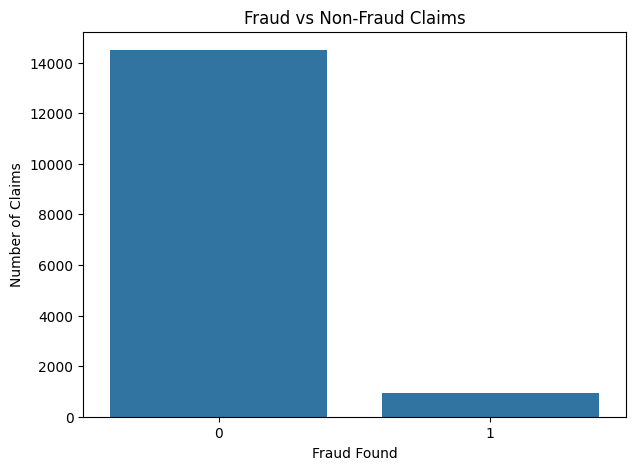

In [18]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="FraudFound_P"
)

plt.title("Fraud vs Non-Fraud Claims")
plt.xlabel("Fraud Found")
plt.ylabel("Number of Claims")

plt.show()

In [19]:
fraud_rate = df["FraudFound_P"].mean() * 100

print(f"Fraud Rate: {fraud_rate:.2f}%")

Fraud Rate: 5.99%


In [20]:
for col in df.columns:
    print("\n" + "=" * 60)
    print(col)
    print(df[col].unique()[:20])


Month
['Dec' 'Jan' 'Oct' 'Jun' 'Feb' 'Nov' 'Apr' 'Mar' 'Aug' 'Jul' 'May' 'Sep']

WeekOfMonth
[5 3 2 4 1]

DayOfWeek
['Wednesday' 'Friday' 'Saturday' 'Monday' 'Tuesday' 'Sunday' 'Thursday']

Make
['Honda' 'Toyota' 'Ford' 'Mazda' 'Chevrolet' 'Pontiac' 'Accura' 'Dodge'
 'Mercury' 'Jaguar' 'Nisson' 'VW' 'Saab' 'Saturn' 'Porche' 'BMW' 'Mecedes'
 'Ferrari' 'Lexus']

AccidentArea
['Urban' 'Rural']

DayOfWeekClaimed
['Tuesday' 'Monday' 'Thursday' 'Friday' 'Wednesday' 'Saturday' 'Sunday'
 '0']

MonthClaimed
['Jan' 'Nov' 'Jul' 'Feb' 'Mar' 'Dec' 'Apr' 'Aug' 'May' 'Jun' 'Sep' 'Oct'
 '0']

WeekOfMonthClaimed
[1 4 2 3 5]

Sex
['Female' 'Male']

MaritalStatus
['Single' 'Married' 'Widow' 'Divorced']

Age
[21 34 47 65 27 20 36  0 30 42 71 52 28 61 38 41 32 40 63 31]

Fault
['Policy Holder' 'Third Party']

PolicyType
['Sport - Liability' 'Sport - Collision' 'Sedan - Liability'
 'Utility - All Perils' 'Sedan - All Perils' 'Sedan - Collision'
 'Utility - Collision' 'Utility - Liability' 'Sport - All Peri

In [21]:
unique_counts = df.nunique().sort_values(ascending=False)

unique_counts

,0
PolicyNumber,15420
Age,66
Make,19
RepNumber,16
MonthClaimed,13
Month,12
PolicyType,9
AgeOfPolicyHolder,9
DayOfWeekClaimed,8
AgeOfVehicle,8


In [22]:
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_columns)

print("\nCategorical Features:")
print(categorical_columns)

Numerical Features:
['WeekOfMonth', 'WeekOfMonthClaimed', 'Age', 'FraudFound_P', 'PolicyNumber', 'RepNumber', 'Deductible', 'DriverRating', 'Year']

Categorical Features:
['Month', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'Sex', 'MaritalStatus', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'BasePolicy']


In [23]:
for col in df.columns:
    if df[col].nunique() > 0.9 * len(df):
        print(
            f"{col}: {df[col].nunique()} unique values "
            f"out of {len(df)}"
        )

PolicyNumber: 15420 unique values out of 15420


In [24]:
DROP_COLUMNS = [
    "PolicyNumber"
]

df_model = df.drop(columns=DROP_COLUMNS)

print("Original shape:", df.shape)
print("Model dataset shape:", df_model.shape)

Original shape: (15420, 33)
Model dataset shape: (15420, 32)


In [25]:
TARGET = "FraudFound_P"

X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (15420, 31)
y shape: (15420,)


In [26]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
WeekOfMonth,15420.0,2.788586,1.287585,1.0,2.0,3.0,4.0,5.0
WeekOfMonthClaimed,15420.0,2.693969,1.259115,1.0,2.0,3.0,4.0,5.0
Age,15420.0,39.855707,13.492377,0.0,31.0,38.0,48.0,80.0
RepNumber,15420.0,8.483268,4.599948,1.0,5.0,8.0,12.0,16.0
Deductible,15420.0,407.704280,43.950998,300.0,400.0,400.0,400.0,700.0
DriverRating,15420.0,2.487808,1.119453,1.0,1.0,2.0,3.0,4.0
Year,15420.0,1994.866472,0.803313,1994.0,1994.0,1995.0,1996.0,1996.0


In [27]:
age_fraud = (
    df.groupby("Age")["FraudFound_P"]
    .mean()
    .sort_values(ascending=False)
)

age_fraud.head(15)

,FraudFound_P
Age,
18,0.166667
17,0.166667
19,0.156250
72,0.133333
67,0.129032
68,0.125000
66,0.119048
16,0.111111
20,0.107143


In [28]:
fraud_by_area = pd.crosstab(
    df["AccidentArea"],
    df["FraudFound_P"],
    normalize="index"
) * 100

fraud_by_area

FraudFound_P,0,1
AccidentArea,,
Rural,91.677096,8.322904
Urban,94.284474,5.715526


In [29]:
fraud_by_policy = pd.crosstab(
    df["PolicyType"],
    df["FraudFound_P"],
    normalize="index"
) * 100

fraud_by_policy.sort_values(
    by=1,
    ascending=False
)

FraudFound_P,0,1
PolicyType,,
Sport - Collision,86.206897,13.793103
Utility - All Perils,87.941176,12.058824
Sedan - All Perils,89.943724,10.056276
Utility - Collision,90.000000,10.000000
Sedan - Collision,93.123209,6.876791
Sedan - Liability,99.278123,0.721877
Sport - All Perils,100.000000,0.000000
Sport - Liability,100.000000,0.000000
Utility - Liability,100.000000,0.000000


In [30]:
fraud_by_vehicle = pd.crosstab(
    df["VehicleCategory"],
    df["FraudFound_P"],
    normalize="index"
) * 100

fraud_by_vehicle

FraudFound_P,0,1
VehicleCategory,,
Sedan,91.779547,8.220453
Sport,98.432251,1.567749
Utility,88.746803,11.253197


In [31]:
fraud_by_rating = pd.crosstab(
    df["DriverRating"],
    df["FraudFound_P"],
    normalize="index"
) * 100

fraud_by_rating

FraudFound_P,0,1
DriverRating,,
1,94.117647,5.882353
2,94.369903,5.630097
3,93.769310,6.230690
4,93.801108,6.198892


In [32]:
fraud_by_previous_claims = pd.crosstab(
    df["PastNumberOfClaims"],
    df["FraudFound_P"],
    normalize="index"
) * 100

fraud_by_previous_claims

FraudFound_P,0,1
PastNumberOfClaims,,
1,93.786734,6.213266
2 to 4,94.639927,5.360073
more than 4,96.616915,3.383085
none,92.210478,7.789522


In [33]:
fraud_by_police_report = pd.crosstab(
    df["PoliceReportFiled"],
    df["FraudFound_P"],
    normalize="index"
) * 100

fraud_by_police_report

FraudFound_P,0,1
PoliceReportFiled,,
No,93.950107,6.049893
Yes,96.261682,3.738318


In [34]:
fraud_by_witness = pd.crosstab(
    df["WitnessPresent"],
    df["FraudFound_P"],
    normalize="index"
) * 100

fraud_by_witness

FraudFound_P,0,1
WitnessPresent,,
No,93.999870,6.000130
Yes,96.551724,3.448276


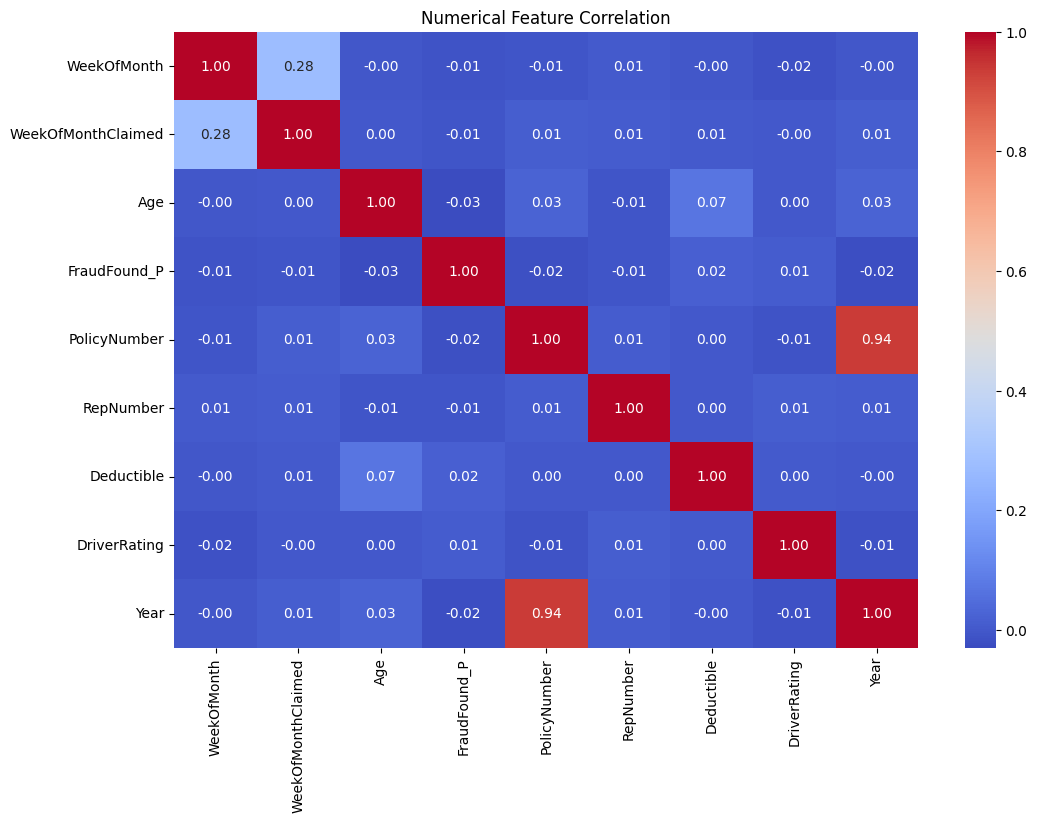

In [35]:
numeric_df = df.select_dtypes(
    include=["int64", "float64"]
)

correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Numerical Feature Correlation")
plt.show()

In [36]:
df_fe = df.copy()

In [37]:
# ── Feature Engineering Step 1: Days_Policy_Accident / Days_Policy_Claim ──

# Ordinal mapping based on business meaning:
# "none"       → 0   (no delay, policy just started)
# "1 to 7"     → 4   (very short: within a week)
# "8 to 15"    → 11  (short: within 2 weeks)
# "15 to 30"   → 22  (moderate)
# "more than 30" → 45 (long delay, highest ordinal)

DAYS_ORDINAL_MAP = {
    "none":          0,
    "1 to 7":        4,
    "8 to 15":       11,
    "15 to 30":      22,
    "more than 30":  45,
}

def convert_days(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    if value in ["none", "nan", "?", ""]:
        return 0  # no delay = 0 days, not missing
    if value in DAYS_ORDINAL_MAP:
        return DAYS_ORDINAL_MAP[value]
    # fallback: try to parse midpoint from "X to Y"
    if "to" in value:
        try:
            parts = value.split("to")
            low = float(parts[0].strip())
            high = float(parts[1].strip())
            return (low + high) / 2
        except Exception:
            return np.nan
    # fallback: direct numeric
    try:
        return float(value)
    except Exception:
        return np.nan

df_fe = df.copy()

df_fe["Days_Policy_Accident_Numeric"] = (
    df_fe["Days_Policy_Accident"].apply(convert_days)
)

df_fe["Days_Policy_Claim_Numeric"] = (
    df_fe["Days_Policy_Claim"].apply(convert_days)
)

print("Unique Days_Policy_Accident values mapped:")
print(df_fe[["Days_Policy_Accident", "Days_Policy_Accident_Numeric"]].drop_duplicates().sort_values("Days_Policy_Accident_Numeric"))
print("\nNull count after conversion:",
      df_fe["Days_Policy_Accident_Numeric"].isnull().sum(),
      df_fe["Days_Policy_Claim_Numeric"].isnull().sum())

Unique Days_Policy_Accident values mapped:
    Days_Policy_Accident  Days_Policy_Accident_Numeric
204                 none                             0
384               1 to 7                             4
550              8 to 15                            11
72              15 to 30                            22
0           more than 30                            45

Null count after conversion: 0 0


In [38]:
# ── Feature Engineering Step 2: Claim_Accident_Delay ──
# Meaningful delay = how many days AFTER accident was claim filed.
# Both columns are now filled (0 = no delay), so subtraction won't produce NaN.

df_fe["Claim_Accident_Delay"] = (
    df_fe["Days_Policy_Claim_Numeric"] -
    df_fe["Days_Policy_Accident_Numeric"]
)

# Clip at 0: negative delay is a data artifact, treat as 0
df_fe["Claim_Accident_Delay"] = df_fe["Claim_Accident_Delay"].clip(lower=0)

print("Claim_Accident_Delay — null count:", df_fe["Claim_Accident_Delay"].isnull().sum())
print("\nSample:")
df_fe[
    ["Days_Policy_Accident", "Days_Policy_Claim",
     "Days_Policy_Accident_Numeric", "Days_Policy_Claim_Numeric",
     "Claim_Accident_Delay"]
].head(8)

Claim_Accident_Delay — null count: 0

Sample:


,Days_Policy_Accident,Days_Policy_Claim,Days_Policy_Accident_Numeric,Days_Policy_Claim_Numeric,Claim_Accident_Delay
0,more than 30,more than 30,45,45,0
1,more than 30,more than 30,45,45,0
2,more than 30,more than 30,45,45,0
3,more than 30,more than 30,45,45,0
4,more than 30,more than 30,45,45,0
5,more than 30,more than 30,45,45,0
6,more than 30,more than 30,45,45,0
7,more than 30,more than 30,45,45,0


In [39]:
claim_mapping = {
    "none": 0,
    "1": 1,
    "2": 2,
    "more than 2": 3
}

df_fe["Previous_Claims_Count"] = (
    df_fe["PastNumberOfClaims"]
    .astype(str)
    .str.lower()
    .map(claim_mapping)
)

In [40]:
def extract_numeric(value):
    if pd.isna(value):
        return np.nan

    value = str(value).lower().strip()

    if value == "new":
        return 0

    numbers = []

    for token in value.replace("-", " ").split():
        try:
            numbers.append(float(token))
        except:
            pass

    if len(numbers) == 1:
        return numbers[0]

    if len(numbers) >= 2:
        return np.mean(numbers[:2])

    return np.nan


df_fe["Vehicle_Age_Numeric"] = (
    df_fe["AgeOfVehicle"]
    .apply(extract_numeric)
)

In [41]:
df_fe["Vehicle_Price_Numeric"] = (
    df_fe["VehiclePrice"]
    .apply(extract_numeric)
)

In [42]:
df_fe["No_Police_Report"] = (
    df_fe["PoliceReportFiled"]
    .astype(str)
    .str.lower()
    .map({
        "yes": 0,
        "no": 1
    })
)

df_fe["No_Witness"] = (
    df_fe["WitnessPresent"]
    .astype(str)
    .str.lower()
    .map({
        "yes": 0,
        "no": 1
    })
)

In [43]:
TARGET = "FraudFound_P"

DROP_FOR_MODEL = [TARGET, "PolicyNumber"]

X = df_fe.drop(columns=DROP_FOR_MODEL, errors="ignore")
y = df_fe[TARGET]

print("Feature matrix X:", X.shape)
print("Target vector  y:", y.shape)
print("Fraud rate       :", round(y.mean() * 100, 2), "%")

Feature matrix X: (15420, 39)
Target vector  y: (15420,)
Fraud rate       : 5.99 %


In [44]:
# (Duplicate X/y definition removed — see cell above)
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (15420, 39) | y shape: (15420,)


In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training: (12336, 39)
Testing : (3084, 39)

Training target distribution:
FraudFound_P
0    0.940175
1    0.059825
Name: proportion, dtype: float64

Testing target distribution:
FraudFound_P
0    0.940013
1    0.059987
Name: proportion, dtype: float64


In [46]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numeric features  :", len(numeric_features), numeric_features)
print("Categorical features:", len(categorical_features), categorical_features)

Numeric features  : 15 ['WeekOfMonth', 'WeekOfMonthClaimed', 'Age', 'RepNumber', 'Deductible', 'DriverRating', 'Year', 'Days_Policy_Accident_Numeric', 'Days_Policy_Claim_Numeric', 'Claim_Accident_Delay', 'Previous_Claims_Count', 'Vehicle_Age_Numeric', 'Vehicle_Price_Numeric', 'No_Police_Report', 'No_Witness']
Categorical features: 24 ['Month', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'Sex', 'MaritalStatus', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'BasePolicy']


In [47]:
# (Duplicate feature detection removed — see cell above)
print("Numeric:", len(numeric_features), "| Categorical:", len(categorical_features))

Numeric: 15 | Categorical: 24


In [48]:
# ── Preprocessing Pipeline ──
# Note: StandardScaler is kept here for compatibility with Logistic Regression.
# Tree-based models (RF, XGB, GB, DT) are scale-invariant — scaler has no effect
# on their predictions but allows one shared preprocessor for all models.

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot",  OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer,  numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessor built successfully.")

Preprocessor built successfully.


In [49]:
# ── Model 1: Logistic Regression (with SMOTE) ──
logistic_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote",        SMOTE(random_state=42)),
    ("classifier",   LogisticRegression(
        max_iter=1000,
        random_state=42,
        n_jobs=-1
    ))
])

logistic_model.fit(X_train, y_train)
print("Logistic Regression trained.")

Logistic Regression trained.


In [50]:
def recall_at_k(y_true, y_prob, k=0.10):
    """Recall among top-k% riskiest claims."""
    n_top = max(1, int(len(y_prob) * k))
    top_idx = np.argsort(y_prob)[::-1][:n_top]
    actual_fraud_in_top = y_true.iloc[top_idx].sum() if hasattr(y_true, "iloc") else y_true[top_idx].sum()
    total_fraud = y_true.sum()
    return float(actual_fraud_in_top / total_fraud) if total_fraud > 0 else 0.0

def precision_at_k(y_true, y_prob, k=0.10):
    """Precision among top-k% riskiest claims."""
    n_top = max(1, int(len(y_prob) * k))
    top_idx = np.argsort(y_prob)[::-1][:n_top]
    actual_fraud_in_top = y_true.iloc[top_idx].sum() if hasattr(y_true, "iloc") else y_true[top_idx].sum()
    return float(actual_fraud_in_top / n_top)

def evaluate_model(model, X_test, y_test, model_name, threshold=0.50):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Use threshold-based predictions for classification metrics
    y_pred_thresh = (y_prob >= threshold).astype(int)

    results = {
        "Model":     model_name,
        "PR-AUC":    round(average_precision_score(y_test, y_prob), 4),
        "ROC-AUC":   round(roc_auc_score(y_test, y_prob), 4),
        "Recall":    round(recall_score(y_test, y_pred_thresh, zero_division=0), 4),
        "Precision": round(precision_score(y_test, y_pred_thresh, zero_division=0), 4),
        "F1":        round(f1_score(y_test, y_pred_thresh, zero_division=0), 4),
        "Recall@5%":   round(recall_at_k(y_test, y_prob, 0.05), 4),
        "Recall@10%":  round(recall_at_k(y_test, y_prob, 0.10), 4),
        "Recall@20%":  round(recall_at_k(y_test, y_prob, 0.20), 4),
        "Precision@5%":   round(precision_at_k(y_test, y_prob, 0.05), 4),
        "Precision@10%":  round(precision_at_k(y_test, y_prob, 0.10), 4),
        "Precision@20%":  round(precision_at_k(y_test, y_prob, 0.20), 4),
    }

    print(f"\n{'='*55}")
    print(f"  {model_name}")
    print(f"{'='*55}")
    for k, v in results.items():
        if k != "Model":
            print(f"  {k:<18}: {v}")
    print("\n  -- Fraud Class Report --")
    print(classification_report(
        y_test, y_pred_thresh,
        target_names=["Non-Fraud", "Fraud"],
        zero_division=0
    ))

    return results, y_pred_thresh, y_prob

print("evaluate_model() and recall_at_k / precision_at_k helpers defined.")

evaluate_model() and recall_at_k / precision_at_k helpers defined.


In [51]:
logistic_results, _, logistic_probs = evaluate_model(
    logistic_model,
    X_test,
    y_test,
    "Logistic Regression"
)


  Logistic Regression
  PR-AUC            : 0.1502
  ROC-AUC           : 0.7982
  Recall            : 0.8216
  Precision         : 0.1301
  F1                : 0.2247
  Recall@5%         : 0.1351
  Recall@10%        : 0.2378
  Recall@20%        : 0.5243
  Precision@5%      : 0.1623
  Precision@10%     : 0.1429
  Precision@20%     : 0.1575

  -- Fraud Class Report --
              precision    recall  f1-score   support

   Non-Fraud       0.98      0.65      0.78      2899
       Fraud       0.13      0.82      0.22       185

    accuracy                           0.66      3084
   macro avg       0.56      0.74      0.50      3084
weighted avg       0.93      0.66      0.75      3084



In [52]:
decision_tree = ImbPipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "smote",
            SMOTE(random_state=42)
        ),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=8,
                min_samples_leaf=10,
                random_state=42
            )
        )
    ]
)

In [53]:
decision_tree.fit(
    X_train,
    y_train
)

print("Decision Tree trained.")

Decision Tree trained.


In [54]:
dt_results, _, dt_probs = evaluate_model(
    decision_tree,
    X_test,
    y_test,
    "Decision Tree"
)


  Decision Tree
  PR-AUC            : 0.1705
  ROC-AUC           : 0.7938
  Recall            : 0.3568
  Precision         : 0.1483
  F1                : 0.2095
  Recall@5%         : 0.1676
  Recall@10%        : 0.2757
  Recall@20%        : 0.4595
  Precision@5%      : 0.2013
  Precision@10%     : 0.1656
  Precision@20%     : 0.138

  -- Fraud Class Report --
              precision    recall  f1-score   support

   Non-Fraud       0.95      0.87      0.91      2899
       Fraud       0.15      0.36      0.21       185

    accuracy                           0.84      3084
   macro avg       0.55      0.61      0.56      3084
weighted avg       0.91      0.84      0.87      3084



In [55]:
# ── Model 3: Random Forest (SMOTE + balanced class_weight) ──
random_forest = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote",        SMOTE(random_state=42)),
    ("classifier",   RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [56]:
random_forest.fit(
    X_train,
    y_train
)

print("Random Forest trained.")

Random Forest trained.


In [57]:
rf_results, _, rf_probs = evaluate_model(
    random_forest,
    X_test,
    y_test,
    "Random Forest"
)


  Random Forest
  PR-AUC            : 0.1719
  ROC-AUC           : 0.8063
  Recall            : 0.1838
  Precision         : 0.1709
  F1                : 0.1771
  Recall@5%         : 0.173
  Recall@10%        : 0.2649
  Recall@20%        : 0.5351
  Precision@5%      : 0.2078
  Precision@10%     : 0.1591
  Precision@20%     : 0.1607

  -- Fraud Class Report --
              precision    recall  f1-score   support

   Non-Fraud       0.95      0.94      0.95      2899
       Fraud       0.17      0.18      0.18       185

    accuracy                           0.90      3084
   macro avg       0.56      0.56      0.56      3084
weighted avg       0.90      0.90      0.90      3084



In [58]:
gradient_boosting = ImbPipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "smote",
            SMOTE(random_state=42)
        ),
        (
            "classifier",
            GradientBoostingClassifier(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

In [59]:
gradient_boosting.fit(
    X_train,
    y_train
)

print("Gradient Boosting trained.")

Gradient Boosting trained.


In [60]:
gb_results, _, gb_probs = evaluate_model(
    gradient_boosting,
    X_test,
    y_test,
    "Gradient Boosting"
)


  Gradient Boosting
  PR-AUC            : 0.2035
  ROC-AUC           : 0.8198
  Recall            : 0.0378
  Precision         : 0.3182
  F1                : 0.0676
  Recall@5%         : 0.1784
  Recall@10%        : 0.3027
  Recall@20%        : 0.5622
  Precision@5%      : 0.2143
  Precision@10%     : 0.1818
  Precision@20%     : 0.1688

  -- Fraud Class Report --
              precision    recall  f1-score   support

   Non-Fraud       0.94      0.99      0.97      2899
       Fraud       0.32      0.04      0.07       185

    accuracy                           0.94      3084
   macro avg       0.63      0.52      0.52      3084
weighted avg       0.90      0.94      0.91      3084



In [61]:
xgb_model = ImbPipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "smote",
            SMOTE(random_state=42)
        ),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [62]:
xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost trained.")

XGBoost trained.


In [63]:
xgb_results, _, xgb_probs = evaluate_model(
    xgb_model,
    X_test,
    y_test,
    "XGBoost"
)


  XGBoost
  PR-AUC            : 0.2531
  ROC-AUC           : 0.846
  Recall            : 0.0378
  Precision         : 0.875
  F1                : 0.0725
  Recall@5%         : 0.2162
  Recall@10%        : 0.3892
  Recall@20%        : 0.6432
  Precision@5%      : 0.2597
  Precision@10%     : 0.2338
  Precision@20%     : 0.1932

  -- Fraud Class Report --
              precision    recall  f1-score   support

   Non-Fraud       0.94      1.00      0.97      2899
       Fraud       0.88      0.04      0.07       185

    accuracy                           0.94      3084
   macro avg       0.91      0.52      0.52      3084
weighted avg       0.94      0.94      0.92      3084



In [64]:
# ── Baseline Model Comparison Table ──
results = pd.DataFrame([
    logistic_results,
    dt_results,
    rf_results,
    gb_results,
    xgb_results
])

print("\nModel comparison sorted by PR-AUC:")
results.sort_values(by="PR-AUC", ascending=False).reset_index(drop=True)


Model comparison sorted by PR-AUC:


,Model,PR-AUC,ROC-AUC,Recall,Precision,F1,Recall@5%,Recall@10%,Recall@20%,Precision@5%,Precision@10%,Precision@20%
0,XGBoost,0.2531,0.8460,0.0378,0.8750,0.0725,0.2162,0.3892,0.6432,0.2597,0.2338,0.1932
1,Gradient Boosting,0.2035,0.8198,0.0378,0.3182,0.0676,0.1784,0.3027,0.5622,0.2143,0.1818,0.1688
2,Random Forest,0.1719,0.8063,0.1838,0.1709,0.1771,0.1730,0.2649,0.5351,0.2078,0.1591,0.1607
3,Decision Tree,0.1705,0.7938,0.3568,0.1483,0.2095,0.1676,0.2757,0.4595,0.2013,0.1656,0.1380
4,Logistic Regression,0.1502,0.7982,0.8216,0.1301,0.2247,0.1351,0.2378,0.5243,0.1623,0.1429,0.1575


In [65]:
# (Duplicate results table removed — see cell above)
results.sort_values("PR-AUC", ascending=False).reset_index(drop=True)

,Model,PR-AUC,ROC-AUC,Recall,Precision,F1,Recall@5%,Recall@10%,Recall@20%,Precision@5%,Precision@10%,Precision@20%
0,XGBoost,0.2531,0.8460,0.0378,0.8750,0.0725,0.2162,0.3892,0.6432,0.2597,0.2338,0.1932
1,Gradient Boosting,0.2035,0.8198,0.0378,0.3182,0.0676,0.1784,0.3027,0.5622,0.2143,0.1818,0.1688
2,Random Forest,0.1719,0.8063,0.1838,0.1709,0.1771,0.1730,0.2649,0.5351,0.2078,0.1591,0.1607
3,Decision Tree,0.1705,0.7938,0.3568,0.1483,0.2095,0.1676,0.2757,0.4595,0.2013,0.1656,0.1380
4,Logistic Regression,0.1502,0.7982,0.8216,0.1301,0.2247,0.1351,0.2378,0.5243,0.1623,0.1429,0.1575


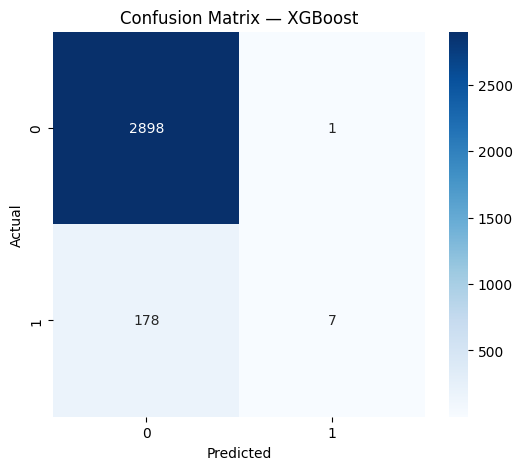

In [66]:
best_model = xgb_model
best_model_name = "XGBoost"

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

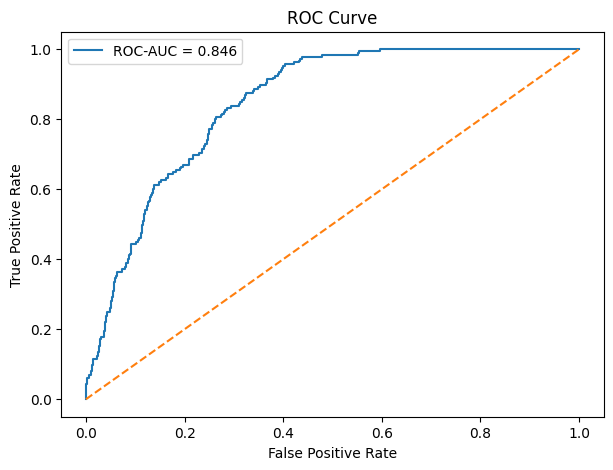

In [67]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

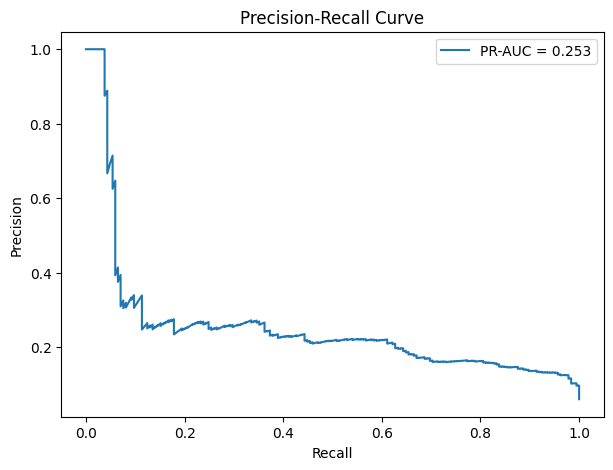

In [68]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_prob
)

pr_auc = average_precision_score(
    y_test,
    y_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f"PR-AUC = {pr_auc:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve")

plt.legend()

plt.show()

In [69]:
risk_scores = pd.DataFrame({
    "Claim_Index": X_test.index,
    "Actual": y_test.values,
    "Fraud_Probability": y_prob
})

risk_scores.head()

,Claim_Index,Actual,Fraud_Probability
0,8922,0,0.005869
1,4274,0,0.082943
2,3408,0,0.002344
3,10675,0,0.130954
4,3285,0,0.032073


In [70]:
# ── assign_risk: threshold-aware risk banding ──
# Thresholds defined based on fraud rate (~15%) and investigation capacity.
# Low   < 0.30  → routine processing
# Medium 0.30–0.60 → flagged for review
# High   > 0.60  → priority investigation

def assign_risk(probability, low_thresh=0.30, high_thresh=0.60):
    if probability < low_thresh:
        return "Low"
    elif probability < high_thresh:
        return "Medium"
    else:
        return "High"

risk_scores["Risk_Level"] = risk_scores["Fraud_Probability"].apply(assign_risk)

# Verify distribution is meaningful (not all Low or all High)
print("Risk distribution:")
print(risk_scores["Risk_Level"].value_counts())
risk_scores.head(10)

Risk distribution:
Risk_Level
Low       3019
Medium      61
High         4
Name: count, dtype: int64


,Claim_Index,Actual,Fraud_Probability,Risk_Level
0,8922,0,0.005869,Low
1,4274,0,0.082943,Low
2,3408,0,0.002344,Low
3,10675,0,0.130954,Low
4,3285,0,0.032073,Low
5,11043,0,0.074669,Low
6,3495,0,0.003326,Low
7,9299,1,0.208585,Low
8,10652,0,0.003222,Low
9,13126,0,0.003423,Low


In [71]:
high_risk_claims = risk_scores.sort_values(
    by="Fraud_Probability",
    ascending=False
)

high_risk_claims.head(20)

,Claim_Index,Actual,Fraud_Probability,Risk_Level
1330,204,1,0.896978,High
1339,3519,1,0.882785,High
1676,2040,1,0.881698,High
1203,9945,1,0.825029,High
304,1456,1,0.527815,Medium
913,5979,1,0.506523,Medium
2950,1811,1,0.505078,Medium
1293,10380,0,0.502973,Medium
1379,9690,1,0.495679,Medium
493,4402,0,0.481715,Medium


In [72]:
risk_distribution = (
    risk_scores["Risk_Level"]
    .value_counts()
)

risk_distribution

,count
Risk_Level,
Low,3019
Medium,61
High,4


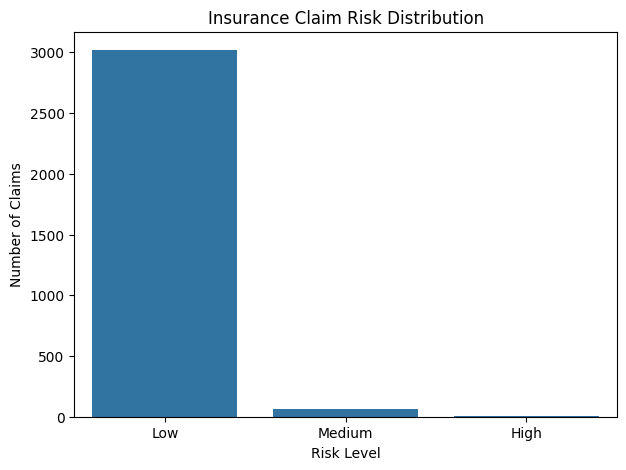

In [73]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=risk_scores,
    x="Risk_Level",
    order=["Low", "Medium", "High"]
)

plt.title("Insurance Claim Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Claims")

plt.show()

In [74]:
# ── Threshold Sweep Analysis ──
threshold_results = []

for thresh in np.arange(0.10, 0.91, 0.05):
    preds = (y_prob >= thresh).astype(int)
    threshold_results.append({
        "Threshold": round(thresh, 2),
        "Precision": round(precision_score(y_test, preds, zero_division=0), 4),
        "Recall":    round(recall_score(y_test, preds, zero_division=0), 4),
        "F1":        round(f1_score(y_test, preds, zero_division=0), 4),
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df

,Threshold,Precision,Recall,F1
0,0.10,0.1616,0.7135,0.2635
1,0.15,0.2198,0.5514,0.3143
2,0.20,0.2675,0.3514,0.3037
3,0.25,0.2500,0.1784,0.2082
4,0.30,0.3231,0.1135,0.1680
5,0.35,0.3333,0.0703,0.1161
6,0.40,0.5238,0.0595,0.1068
7,0.45,0.6667,0.0541,0.1000
8,0.50,0.8750,0.0378,0.0725
9,0.55,1.0000,0.0216,0.0423


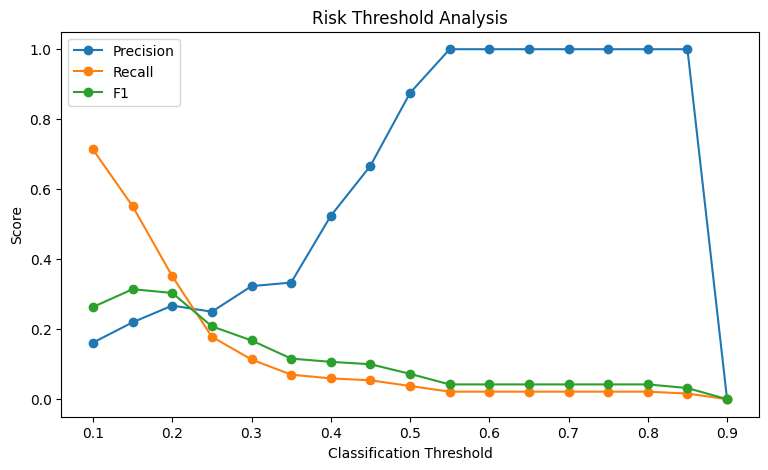

In [75]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.title("Risk Threshold Analysis")

plt.legend()

plt.show()

In [76]:
# ── Optimal Threshold Selection ──
# Fraud investigation objective: maximize Recall while keeping Precision acceptable.
# Strategy: among thresholds with Recall >= 0.60, pick the one with highest F1.

qualified = threshold_df[threshold_df["Recall"] >= 0.60]

if not qualified.empty:
    best_row = qualified.loc[qualified["F1"].idxmax()]
    OPERATIONAL_THRESHOLD = float(best_row["Threshold"])
    print(f"Optimal threshold (Recall >= 0.60, best F1): {OPERATIONAL_THRESHOLD}")
    print(best_row.to_string())
else:
    # Fallback: pure F1 maximiser
    best_row = threshold_df.loc[threshold_df["F1"].idxmax()]
    OPERATIONAL_THRESHOLD = float(best_row["Threshold"])
    print(f"Fallback — highest F1 threshold: {OPERATIONAL_THRESHOLD}")
    print(best_row.to_string())

y_pred_operational = (y_prob >= OPERATIONAL_THRESHOLD).astype(int)
print("\nClassification Report at Operational Threshold:")
print(classification_report(
    y_test, y_pred_operational,
    target_names=["Non-Fraud", "Fraud"],
    zero_division=0
))

Optimal threshold (Recall >= 0.60, best F1): 0.1
Threshold    0.1000
Precision    0.1616
Recall       0.7135
F1           0.2635

Classification Report at Operational Threshold:
              precision    recall  f1-score   support

   Non-Fraud       0.98      0.76      0.86      2899
       Fraud       0.16      0.71      0.26       185

    accuracy                           0.76      3084
   macro avg       0.57      0.74      0.56      3084
weighted avg       0.93      0.76      0.82      3084



In [77]:
fitted_preprocessor = (
    best_model.named_steps["preprocessor"]
)

fitted_classifier = (
    best_model.named_steps["classifier"]
)

In [78]:
X_test_transformed = (
    fitted_preprocessor.transform(X_test)
)

print(
    "Transformed shape:",
    X_test_transformed.shape
)

Transformed shape: (3084, 155)


In [79]:
feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

print("Number of transformed features:", len(feature_names))

print(feature_names[:30])

Number of transformed features: 155
['num__WeekOfMonth' 'num__WeekOfMonthClaimed' 'num__Age' 'num__RepNumber'
 'num__Deductible' 'num__DriverRating' 'num__Year'
 'num__Days_Policy_Accident_Numeric' 'num__Days_Policy_Claim_Numeric'
 'num__Claim_Accident_Delay' 'num__Previous_Claims_Count'
 'num__Vehicle_Age_Numeric' 'num__Vehicle_Price_Numeric'
 'num__No_Police_Report' 'num__No_Witness' 'cat__Month_Apr'
 'cat__Month_Aug' 'cat__Month_Dec' 'cat__Month_Feb' 'cat__Month_Jan'
 'cat__Month_Jul' 'cat__Month_Jun' 'cat__Month_Mar' 'cat__Month_May'
 'cat__Month_Nov' 'cat__Month_Oct' 'cat__Month_Sep'
 'cat__DayOfWeek_Friday' 'cat__DayOfWeek_Monday' 'cat__DayOfWeek_Saturday']


In [80]:
explainer = shap.TreeExplainer(
    fitted_classifier
)

shap_values = explainer.shap_values(
    X_test_transformed
)

print("SHAP values generated.")

SHAP values generated.


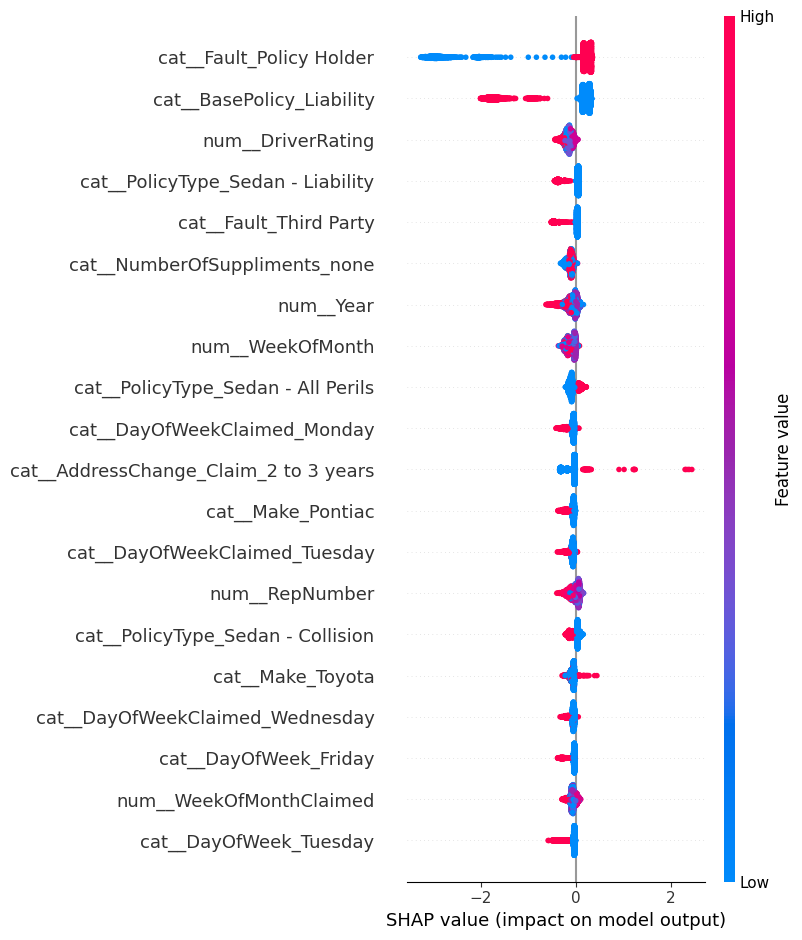

In [81]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    show=True
)

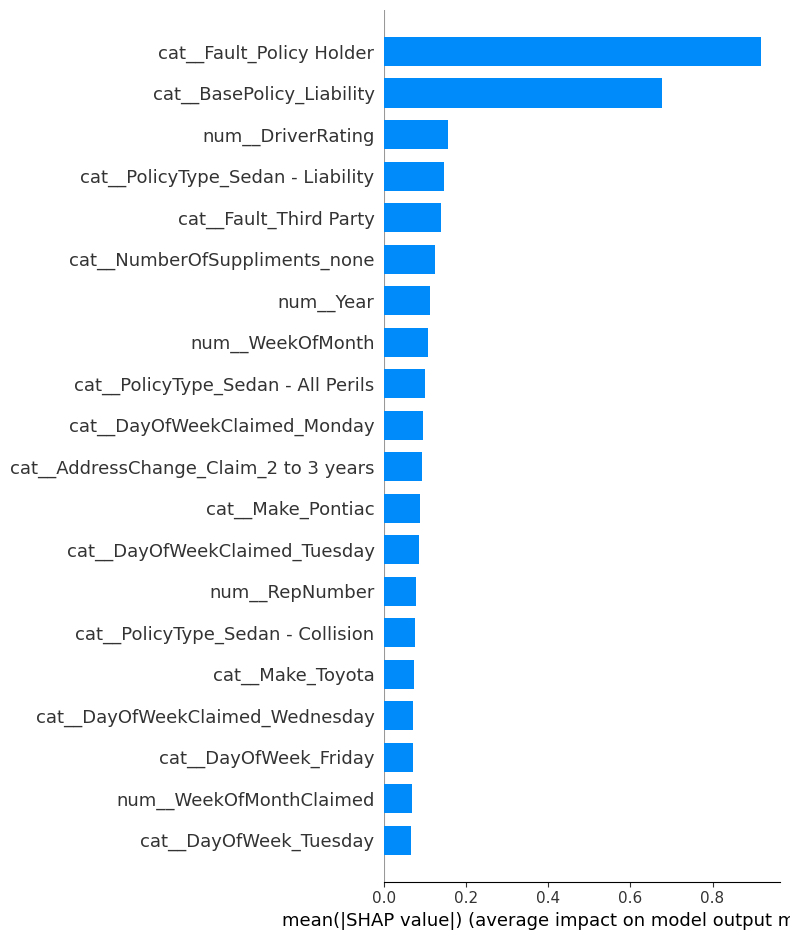

In [82]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar",
    show=True
)

In [83]:
sample_index = 0

sample_claim = X_test.iloc[[sample_index]]

sample_probability = best_model.predict_proba(
    sample_claim
)[0, 1]

print(
    f"Fraud Probability: "
    f"{sample_probability * 100:.2f}%"
)

print(
    "Risk Level:",
    assign_risk(sample_probability)
)

Fraud Probability: 0.59%
Risk Level: Low


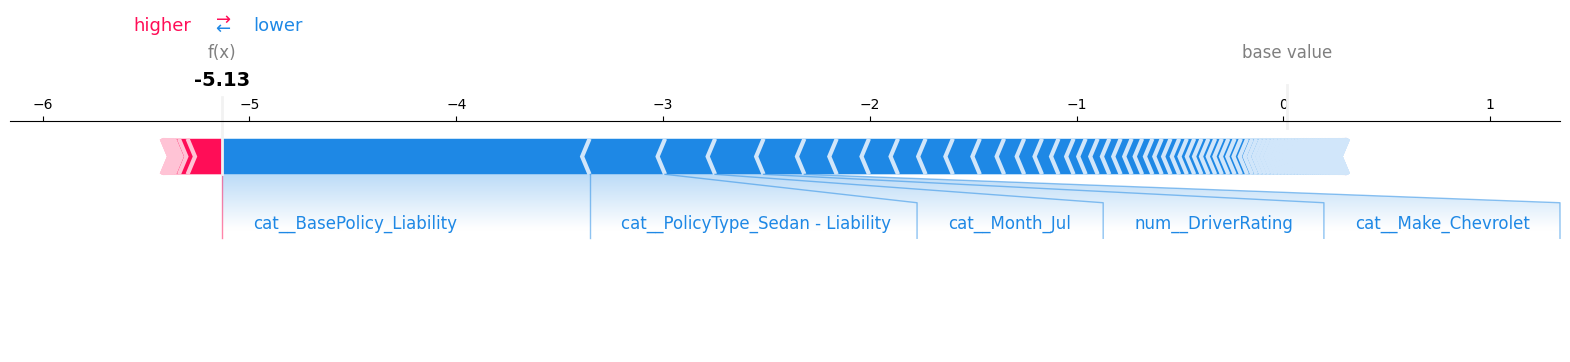

In [84]:
sample_transformed = (
    fitted_preprocessor.transform(
        sample_claim
    )
)

sample_shap_values = (
    explainer.shap_values(
        sample_transformed
    )
)

shap.force_plot(
    explainer.expected_value,
    sample_shap_values[0],
    feature_names=feature_names,
    matplotlib=True
)

plt.show()

In [85]:
shap_contributions = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": sample_shap_values[0]
})

shap_contributions["Absolute_Impact"] = (
    shap_contributions["SHAP_Value"]
    .abs()
)

top_features = (
    shap_contributions
    .sort_values(
        by="Absolute_Impact",
        ascending=False
    )
    .head(10)
)

top_features

,Feature,SHAP_Value,Absolute_Impact
154,cat__BasePolicy_Liability,-1.776540,1.776540
86,cat__PolicyType_Sedan - Liability,-0.365187,0.365187
20,cat__Month_Jul,-0.241913,0.241913
5,num__DriverRating,-0.234493,0.234493
36,cat__Make_Chevrolet,-0.197420,0.197420
82,cat__Fault_Policy Holder,0.167463,0.167463
3,num__RepNumber,-0.156380,0.156380
56,cat__DayOfWeekClaimed_Friday,-0.155825,0.155825
94,cat__VehicleCategory_Sport,-0.140522,0.140522
6,num__Year,-0.133448,0.133448


In [86]:
# ── Human-Readable Feature Name Mapping ──
FEATURE_LABEL_MAP = {
    "Days_Policy_Accident_Numeric":  "Time between policy start and accident",
    "Days_Policy_Claim_Numeric":     "Time between policy start and claim filing",
    "Claim_Accident_Delay":          "Delay between accident and claim filing",
    "Previous_Claims_Count":         "Number of previous claims",
    "Vehicle_Age_Numeric":           "Age of vehicle (years)",
    "Vehicle_Price_Numeric":         "Vehicle price range",
    "No_Police_Report":              "No police report filed",
    "No_Witness":                    "No witness present",
    "Age":                           "Age of policy holder",
    "DriverRating":                  "Driver risk rating",
    "Year":                          "Year of incident",
    "WeekOfMonth":                   "Week of month of incident",
    "WeekOfMonthClaimed":            "Week of month claim was filed",
    "RepNumber":                     "Representative number",
    "Deductible":                    "Policy deductible amount",
    "DriverRating":                  "Driver rating score",
}

def human_readable_name(raw_name):
    """Convert pipeline-prefixed feature names to analyst-friendly labels."""
    # Strip sklearn pipeline prefix (e.g. num__Age, cat__Make_Honda)
    clean = raw_name.replace("num__", "").replace("cat__", "")
    # Check direct map
    if clean in FEATURE_LABEL_MAP:
        return FEATURE_LABEL_MAP[clean]
    # For OHE features: split at last underscore group
    parts = clean.rsplit("_", 1)
    base = parts[0]
    if base in FEATURE_LABEL_MAP:
        return f"{FEATURE_LABEL_MAP[base]} = {parts[1] if len(parts) > 1 else ''}"
    return clean.replace("_", " ").title()

def generate_explanation(shap_values_row, feature_names, top_n=5):
    """
    Returns top risk-increasing and risk-decreasing factors
    in analyst-friendly language. No 'fraud confirmed' language used.
    """
    df_exp = pd.DataFrame({
        "raw_feature": feature_names,
        "shap_value":  shap_values_row
    })
    df_exp["abs_impact"] = df_exp["shap_value"].abs()
    df_exp["label"] = df_exp["raw_feature"].apply(human_readable_name)
    df_exp = df_exp.sort_values("abs_impact", ascending=False).head(top_n * 2)

    risk_factors = []
    protective_factors = []

    for _, row in df_exp.iterrows():
        entry = {
            "feature": row["label"],
            "shap_value": round(float(row["shap_value"]), 4),
        }
        if row["shap_value"] > 0:
            entry["analyst_note"] = f"{row['label']} contributed to higher estimated risk."
            risk_factors.append(entry)
        else:
            entry["analyst_note"] = f"{row['label']} reduced the estimated risk."
            protective_factors.append(entry)

    return {
        "top_risk_factors":       risk_factors[:top_n],
        "top_protective_factors": protective_factors[:top_n],
    }

print("generate_explanation() with human-readable names defined.")

generate_explanation() with human-readable names defined.


In [87]:
sample_transformed = fitted_preprocessor.transform(sample_claim)
sample_shap_vals   = explainer.shap_values(sample_transformed)

exp = generate_explanation(sample_shap_vals[0], feature_names, top_n=5)

print("=== TOP RISK FACTORS (increase fraud risk) ===")
for f in exp["top_risk_factors"]:
    print(f"  - {f['analyst_note']} (SHAP={f['shap_value']:.4f})")

print("\n=== PROTECTIVE FACTORS (reduce fraud risk) ===")
for f in exp["top_protective_factors"]:
    print(f"  - {f['analyst_note']} (SHAP={f['shap_value']:.4f})")

=== TOP RISK FACTORS (increase fraud risk) ===
  - Fault Policy Holder contributed to higher estimated risk. (SHAP=0.1675)

=== PROTECTIVE FACTORS (reduce fraud risk) ===
  - Basepolicy Liability reduced the estimated risk. (SHAP=-1.7765)
  - Policytype Sedan - Liability reduced the estimated risk. (SHAP=-0.3652)
  - Month Jul reduced the estimated risk. (SHAP=-0.2419)
  - Driver rating score reduced the estimated risk. (SHAP=-0.2345)
  - Make Chevrolet reduced the estimated risk. (SHAP=-0.1974)


In [88]:
def predict_claim_risk(
    claim_data,
    model,
    preprocessor,
    explainer,
    feature_names,
    threshold=0.50,
    model_version="1.0.0"
):
    """
    Production inference function.
    claim_data: dict of raw feature values (same columns as X_train).
    Returns structured risk assessment — no 'fraud confirmed' language.
    """
    claim_df = pd.DataFrame([claim_data])

    # Predict probability
    probability = float(model.predict_proba(claim_df)[0, 1])
    prediction  = int(probability >= threshold)
    risk_score  = round(probability * 100, 2)
    risk_level  = assign_risk(probability)

    # SHAP explanation via preprocessor inside the model pipeline
    transformed = preprocessor.transform(claim_df)
    shap_vals   = explainer.shap_values(transformed)

    explanation = generate_explanation(shap_vals[0], feature_names, top_n=5)

    return {
        "fraud_probability":       probability,
        "risk_score":              risk_score,
        "risk_level":              risk_level,
        "prediction":              prediction,
        "top_risk_factors":        explanation["top_risk_factors"],
        "top_protective_factors":  explanation["top_protective_factors"],
        "model_version":           model_version,
    }

print("predict_claim_risk() defined — production-ready.")

predict_claim_risk() defined — production-ready.


In [89]:
# Demo: run prediction on first test claim (using current best_model)
example_claim = X_test.iloc[0].to_dict()

result = predict_claim_risk(
    example_claim,
    model=best_model,
    preprocessor=fitted_preprocessor,
    explainer=explainer,
    feature_names=feature_names,
    threshold=OPERATIONAL_THRESHOLD
)

print(f"Fraud Probability : {result['fraud_probability']*100:.2f}%")
print(f"Risk Score        : {result['risk_score']}")
print(f"Risk Level        : {result['risk_level']}")
print(f"Prediction        : {'High Risk' if result['prediction'] else 'Low Risk'}")
print(f"\nTop Risk Factors:")
for f in result["top_risk_factors"]:
    print(f"  - {f['analyst_note']}")
print(f"\nProtective Factors:")
for f in result["top_protective_factors"]:
    print(f"  - {f['analyst_note']}")

Fraud Probability : 0.59%
Risk Score        : 0.59
Risk Level        : Low
Prediction        : Low Risk

Top Risk Factors:
  - Fault Policy Holder contributed to higher estimated risk.

Protective Factors:
  - Basepolicy Liability reduced the estimated risk.
  - Policytype Sedan - Liability reduced the estimated risk.
  - Month Jul reduced the estimated risk.
  - Driver rating score reduced the estimated risk.
  - Make Chevrolet reduced the estimated risk.


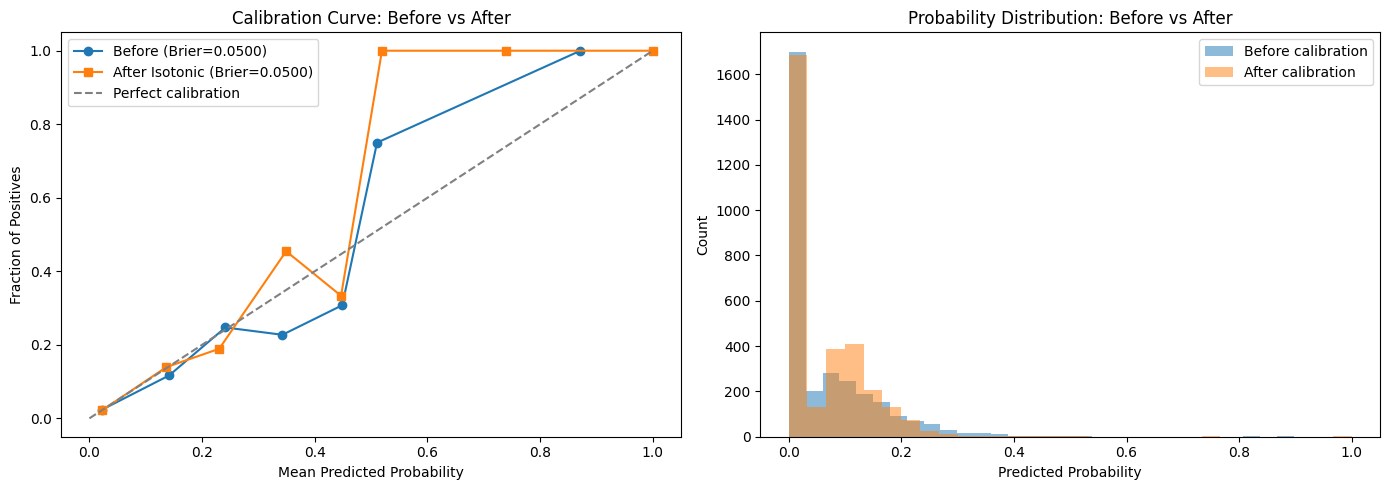

Brier Score BEFORE calibration: 0.0500
Brier Score AFTER  calibration: 0.0500
(Lower Brier score = better calibrated probabilities)


In [90]:
# ── Probability Calibration ──
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss

# Before calibration
brier_before = brier_score_loss(y_test, y_prob)
prob_true_before, prob_pred_before = calibration_curve(y_test, y_prob, n_bins=10)

# Apply Isotonic calibration on the best model's raw classifier
# Use a wrapper since we have a pipeline
from sklearn.base import clone

# Get raw probabilities from the full pipeline
calibrated_pipeline = CalibratedClassifierCV(
    estimator=clone(best_model),
    method="isotonic",
    cv=3
)
calibrated_pipeline.fit(X_train, y_train)

y_prob_cal = calibrated_pipeline.predict_proba(X_test)[:, 1]
brier_after = brier_score_loss(y_test, y_prob_cal)

prob_true_after, prob_pred_after = calibration_curve(y_test, y_prob_cal, n_bins=10)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(prob_pred_before, prob_true_before, marker="o", label=f"Before (Brier={brier_before:.4f})")
axes[0].plot(prob_pred_after,  prob_true_after,  marker="s", label=f"After Isotonic (Brier={brier_after:.4f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
axes[0].set_xlabel("Mean Predicted Probability")
axes[0].set_ylabel("Fraction of Positives")
axes[0].set_title("Calibration Curve: Before vs After")
axes[0].legend()

axes[1].hist(y_prob,     bins=30, alpha=0.5, label="Before calibration")
axes[1].hist(y_prob_cal, bins=30, alpha=0.5, label="After calibration")
axes[1].set_xlabel("Predicted Probability")
axes[1].set_ylabel("Count")
axes[1].set_title("Probability Distribution: Before vs After")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Brier Score BEFORE calibration: {brier_before:.4f}")
print(f"Brier Score AFTER  calibration: {brier_after:.4f}")
print("(Lower Brier score = better calibrated probabilities)")

In [91]:
# ── Stratified 5-Fold Cross-Validation Comparison ──
# Cross-validate ALL models on PR-AUC (more meaningful than accuracy for fraud)

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    "Logistic Regression": logistic_model,
    "Decision Tree":       decision_tree,
    "Random Forest":       random_forest,
    "Gradient Boosting":   gradient_boosting,
    "XGBoost":             xgb_model,
}

cv_results = []
print("Running 5-Fold Stratified CV on all models (scoring=PR-AUC)...")

for name, model in cv_models.items():
    scores = cross_val_score(
        model, X, y,
        cv=cv_strategy,
        scoring="average_precision",
        n_jobs=-1
    )
    cv_results.append({
        "Model":       name,
        "CV PR-AUC Mean": round(scores.mean(), 4),
        "CV PR-AUC Std":  round(scores.std(),  4),
    })
    print(f"  {name}: {scores.mean():.4f} (+/- {scores.std():.4f})")

cv_df = pd.DataFrame(cv_results).sort_values("CV PR-AUC Mean", ascending=False)
print("\nCross-Validation Results:")
cv_df

Running 5-Fold Stratified CV on all models (scoring=PR-AUC)...
  Logistic Regression: 0.1583 (+/- 0.0123)
  Decision Tree: 0.1743 (+/- 0.0086)
  Random Forest: 0.1789 (+/- 0.0196)
  Gradient Boosting: 0.2195 (+/- 0.0105)
  XGBoost: 0.2681 (+/- 0.0137)

Cross-Validation Results:


,Model,CV PR-AUC Mean,CV PR-AUC Std
4,XGBoost,0.2681,0.0137
3,Gradient Boosting,0.2195,0.0105
2,Random Forest,0.1789,0.0196
1,Decision Tree,0.1743,0.0086
0,Logistic Regression,0.1583,0.0123


In [92]:
param_grid = {
    "classifier__n_estimators": [
        200,
        300,
        500
    ],

    "classifier__max_depth": [
        3,
        5,
        7
    ],

    "classifier__learning_rate": [
        0.03,
        0.05,
        0.1
    ],

    "classifier__subsample": [
        0.7,
        0.8,
        1.0
    ],

    "classifier__colsample_bytree": [
        0.7,
        0.8,
        1.0
    ]
}

In [93]:
# cv_strategy is already defined above (StratifiedKFold n_splits=5)
# Re-affirm for tuning phase
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("CV strategy confirmed:", cv_strategy)

CV strategy confirmed: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [94]:
# ── RandomizedSearchCV on a FRESH unfitted XGB template ──
# Important: pass a fresh (unfitted) pipeline clone to avoid state confusion

from sklearn.base import clone

xgb_tuning_template = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote",        SMOTE(random_state=42)),
    ("classifier",   XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "classifier__n_estimators":    [200, 300, 500],
    "classifier__max_depth":       [3, 5, 7],
    "classifier__learning_rate":   [0.03, 0.05, 0.1],
    "classifier__subsample":       [0.7, 0.8, 1.0],
    "classifier__colsample_bytree":[0.7, 0.8, 1.0],
}

random_search = RandomizedSearchCV(
    estimator=xgb_tuning_template,
    param_distributions=param_grid,
    n_iter=15,
    scoring="average_precision",
    cv=cv_strategy,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)
print("\nBest params:", random_search.best_params_)
print("Best PR-AUC (CV):", round(random_search.best_score_, 4))

Fitting 5 folds for each of 15 candidates, totalling 75 fits

Best params: {'classifier__subsample': 1.0, 'classifier__n_estimators': 500, 'classifier__max_depth': 7, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 1.0}
Best PR-AUC (CV): 0.2626


In [95]:
# (Duplicate RandomizedSearchCV removed — tuning done in cell above)
print("Tuning complete. Best estimator stored in random_search.best_estimator_")

Tuning complete. Best estimator stored in random_search.best_estimator_


In [96]:
tuned_model = random_search.best_estimator_

tuned_results, tuned_pred, tuned_prob = evaluate_model(
    tuned_model,
    X_test,
    y_test,
    "Tuned XGBoost",
    threshold=OPERATIONAL_THRESHOLD
)


  Tuned XGBoost
  PR-AUC            : 0.2774
  ROC-AUC           : 0.8533
  Recall            : 0.5676
  Precision         : 0.2092
  F1                : 0.3057
  Recall@5%         : 0.2595
  Recall@10%        : 0.4054
  Recall@20%        : 0.6378
  Precision@5%      : 0.3117
  Precision@10%     : 0.2435
  Precision@20%     : 0.1916

  -- Fraud Class Report --
              precision    recall  f1-score   support

   Non-Fraud       0.97      0.86      0.91      2899
       Fraud       0.21      0.57      0.31       185

    accuracy                           0.85      3084
   macro avg       0.59      0.72      0.61      3084
weighted avg       0.92      0.85      0.88      3084



In [97]:
# ── Final Model Selection — Composite Score ──
# Weighted by fraud detection priorities: PR-AUC > Recall > F1 > Recall@10%

all_results = pd.DataFrame([
    logistic_results,
    dt_results,
    rf_results,
    gb_results,
    xgb_results,
    tuned_results
])

all_results["Composite_Score"] = (
    0.35 * all_results["PR-AUC"]     +
    0.25 * all_results["Recall"]     +
    0.20 * all_results["F1"]         +
    0.20 * all_results["Recall@10%"]
)

all_results_sorted = all_results.sort_values("Composite_Score", ascending=False)
print("Model ranking by composite fraud detection score:")
all_results_sorted[["Model","PR-AUC","ROC-AUC","Recall","Precision","F1",
                     "Recall@10%","Composite_Score"]]

Model ranking by composite fraud detection score:


,Model,PR-AUC,ROC-AUC,Recall,Precision,F1,Recall@10%,Composite_Score
5,Tuned XGBoost,0.2774,0.8533,0.5676,0.2092,0.3057,0.4054,0.381210
0,Logistic Regression,0.1502,0.7982,0.8216,0.1301,0.2247,0.2378,0.350470
1,Decision Tree,0.1705,0.7938,0.3568,0.1483,0.2095,0.2757,0.245915
2,Random Forest,0.1719,0.8063,0.1838,0.1709,0.1771,0.2649,0.194515
4,XGBoost,0.2531,0.8460,0.0378,0.8750,0.0725,0.3892,0.190375
3,Gradient Boosting,0.2035,0.8198,0.0378,0.3182,0.0676,0.3027,0.154735


In [98]:
best_model_row = all_results_sorted.iloc[0]
FINAL_MODEL_NAME = best_model_row["Model"]

model_map = {
    "Logistic Regression": logistic_model,
    "Decision Tree":       decision_tree,
    "Random Forest":       random_forest,
    "Gradient Boosting":   gradient_boosting,
    "XGBoost":             xgb_model,
    "Tuned XGBoost":       tuned_model,
}

FINAL_MODEL = model_map[FINAL_MODEL_NAME]

print(f"Final model selected : {FINAL_MODEL_NAME}")
print(f"Composite score      : {best_model_row['Composite_Score']:.4f}")
print(f"PR-AUC               : {best_model_row['PR-AUC']:.4f}")
print(f"Recall               : {best_model_row['Recall']:.4f}")
print(f"F1                   : {best_model_row['F1']:.4f}")
print(f"Recall@10%           : {best_model_row['Recall@10%']:.4f}")

Final model selected : Tuned XGBoost
Composite score      : 0.3812
PR-AUC               : 0.2774
Recall               : 0.5676
F1                   : 0.3057
Recall@10%           : 0.4054


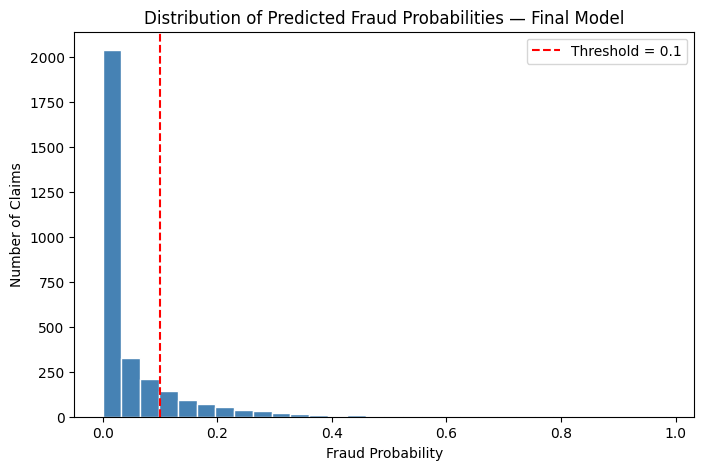

In [99]:
final_probabilities = FINAL_MODEL.predict_proba(X_test)[:, 1]

plt.figure(figsize=(8, 5))
plt.hist(final_probabilities, bins=30, color="steelblue", edgecolor="white")
plt.axvline(OPERATIONAL_THRESHOLD, color="red", linestyle="--",
            label=f"Threshold = {OPERATIONAL_THRESHOLD}")
plt.xlabel("Fraud Probability")
plt.ylabel("Number of Claims")
plt.title("Distribution of Predicted Fraud Probabilities — Final Model")
plt.legend()
plt.show()

In [100]:
final_predictions = (final_probabilities >= OPERATIONAL_THRESHOLD).astype(int)

final_risk_df = pd.DataFrame({
    "Claim_Index":       X_test.index,
    "Actual_Fraud":      y_test.values,
    "Fraud_Probability": final_probabilities,
    "Risk_Level":        [assign_risk(p) for p in final_probabilities],
    "Predicted_Fraud":   final_predictions
})

final_risk_df = final_risk_df.sort_values("Fraud_Probability", ascending=False)

print("Risk distribution of final predictions:")
print(final_risk_df["Risk_Level"].value_counts())
final_risk_df.head(20)

Risk distribution of final predictions:
Risk_Level
Low       2994
Medium      74
High        16
Name: count, dtype: int64


,Claim_Index,Actual_Fraud,Fraud_Probability,Risk_Level,Predicted_Fraud
1676,2040,1,0.983465,High,1
1330,204,1,0.968714,High,1
1203,9945,1,0.967997,High,1
1339,3519,1,0.935469,High,1
1078,6177,1,0.809178,High,1
1379,9690,1,0.788482,High,1
2950,1811,1,0.749470,High,1
1745,6076,0,0.729306,High,1
1628,3250,1,0.692177,High,1
166,10724,1,0.672072,High,1


In [101]:
# ── Dashboard Preview ──
# Note: Dataset (fraud_oracle.csv) does not contain an actual Claim Amount column.
# We do NOT fabricate or impute a claim amount. The dashboard will show
# PolicyNumber, Risk_Level, and Fraud_Probability only.

claim_dashboard = df.loc[final_risk_df["Claim_Index"]].copy()

claim_dashboard["Fraud_Probability"] = (
    final_risk_df.set_index("Claim_Index")["Fraud_Probability"]
)
claim_dashboard["Risk_Level"] = (
    final_risk_df.set_index("Claim_Index")["Risk_Level"]
)

display_cols = ["PolicyNumber", "Fraud_Probability", "Risk_Level"]
print("\nTop 10 Highest Risk Claims:")
claim_dashboard[display_cols].head(10)


Top 10 Highest Risk Claims:


,PolicyNumber,Fraud_Probability,Risk_Level
2040,2041,0.983465,High
204,205,0.968714,High
9945,9946,0.967997,High
3519,3520,0.935469,High
6177,6178,0.809178,High
9690,9691,0.788482,High
1811,1812,0.749470,High
6076,6077,0.729306,High
3250,3251,0.692177,High
10724,10725,0.672072,High


In [102]:
# ── Save Production Artifact (single file) ──
# The full ImbPipeline already contains preprocessor + SMOTE + classifier.
# FastAPI only needs to load this single file — no manual preprocessing needed.

MODEL_PATH = "insurance_fraud_model.pkl"
joblib.dump(FINAL_MODEL, MODEL_PATH)
print(f"Production model saved: {MODEL_PATH}")

# Verify saved model can be reloaded and produces same predictions
_reloaded = joblib.load(MODEL_PATH)
_reload_probs = _reloaded.predict_proba(X_test[:5])[:, 1]
_orig_probs   = FINAL_MODEL.predict_proba(X_test[:5])[:, 1]
assert np.allclose(_reload_probs, _orig_probs), "Model reload verification FAILED!"
print("Model reload verification: PASSED")

Production model saved: insurance_fraud_model.pkl
Model reload verification: PASSED


In [103]:
# ── Save Model Metadata ──
final_preprocessor_for_meta = FINAL_MODEL.named_steps["preprocessor"]
final_feature_names_meta    = final_preprocessor_for_meta.get_feature_names_out().tolist()

metadata = {
    "model_name":          FINAL_MODEL_NAME,
    "model_version":       MODEL_VERSION,
    "target":              TARGET,
    "operational_threshold": OPERATIONAL_THRESHOLD,
    "risk_bands": {
        "Low":    "probability < 0.30",
        "Medium": "0.30 <= probability < 0.60",
        "High":   "probability >= 0.60"
    },
    "raw_feature_columns": X.columns.tolist(),
    "transformed_feature_names": final_feature_names_meta,
    "numeric_features":    numeric_features,
    "categorical_features": categorical_features,
    "brier_score_before_calibration": round(brier_before, 4),
    "brier_score_after_calibration":  round(brier_after, 4),
    "claim_amount_in_dataset": False,  # explicitly flagged
}

joblib.dump(metadata, "model_metadata.pkl")
print("Metadata saved.")
for k, v in metadata.items():
    if k not in ("raw_feature_columns", "transformed_feature_names"):
        print(f"  {k}: {v}")

Metadata saved.
  model_name: Tuned XGBoost
  model_version: 1.0.0
  target: FraudFound_P
  operational_threshold: 0.1
  risk_bands: {'Low': 'probability < 0.30', 'Medium': '0.30 <= probability < 0.60', 'High': 'probability >= 0.60'}
  numeric_features: ['WeekOfMonth', 'WeekOfMonthClaimed', 'Age', 'RepNumber', 'Deductible', 'DriverRating', 'Year', 'Days_Policy_Accident_Numeric', 'Days_Policy_Claim_Numeric', 'Claim_Accident_Delay', 'Previous_Claims_Count', 'Vehicle_Age_Numeric', 'Vehicle_Price_Numeric', 'No_Police_Report', 'No_Witness']
  categorical_features: ['Month', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'Sex', 'MaritalStatus', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'BasePolicy']
  brier_score_before_calibration: 0.0

In [104]:
feature_info = {
    "numeric_features":    numeric_features,
    "categorical_features": categorical_features,
    "all_raw_features":    X.columns.tolist(),
    "engineered_features": [
        "Days_Policy_Accident_Numeric",
        "Days_Policy_Claim_Numeric",
        "Claim_Accident_Delay",
        "Previous_Claims_Count",
        "Vehicle_Age_Numeric",
        "Vehicle_Price_Numeric",
        "No_Police_Report",
        "No_Witness",
    ]
}

joblib.dump(feature_info, "feature_info.pkl")
print("Feature info saved.")

Feature info saved.


In [105]:
final_risk_df.to_csv("insurance_fraud_predictions.csv", index=False)
print("Prediction results saved to: insurance_fraud_predictions.csv")

Prediction results saved to: insurance_fraud_predictions.csv


In [106]:
try:
    from google.colab import files
    files.download("insurance_fraud_model.pkl")
    files.download("model_metadata.pkl")
    files.download("feature_info.pkl")
    files.download("insurance_fraud_predictions.csv")
    print("Files downloaded.")
except (ImportError, Exception):
    print("Not in Colab — files saved locally in current directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Files downloaded.


In [107]:
final_metrics = {
    "Model":     FINAL_MODEL_NAME,
    "PR-AUC":    round(average_precision_score(y_test, final_probabilities), 4),
    "ROC-AUC":   round(roc_auc_score(y_test, final_probabilities), 4),
    "Precision": round(precision_score(y_test, final_predictions, zero_division=0), 4),
    "Recall":    round(recall_score(y_test, final_predictions, zero_division=0), 4),
    "F1":        round(f1_score(y_test, final_predictions, zero_division=0), 4),
    "Recall@5%":    round(recall_at_k(y_test, final_probabilities, 0.05), 4),
    "Recall@10%":   round(recall_at_k(y_test, final_probabilities, 0.10), 4),
    "Recall@20%":   round(recall_at_k(y_test, final_probabilities, 0.20), 4),
    "Precision@5%":  round(precision_at_k(y_test, final_probabilities, 0.05), 4),
    "Precision@10%": round(precision_at_k(y_test, final_probabilities, 0.10), 4),
    "Precision@20%": round(precision_at_k(y_test, final_probabilities, 0.20), 4),
    "Threshold": OPERATIONAL_THRESHOLD,
}

final_report = pd.DataFrame([final_metrics])
print("\nFINAL MODEL PERFORMANCE REPORT")
print("=" * 60)
final_report.T


FINAL MODEL PERFORMANCE REPORT


,0
Model,Tuned XGBoost
PR-AUC,0.2774
ROC-AUC,0.8533
Precision,0.2092
Recall,0.5676
F1,0.3057
Recall@5%,0.2595
Recall@10%,0.4054
Recall@20%,0.6378
Precision@5%,0.3117


In [108]:
print("Final Model Classification Report:")
print(classification_report(
    y_test, final_predictions,
    target_names=["Non-Fraud", "Fraud"],
    zero_division=0
))

Final Model Classification Report:
              precision    recall  f1-score   support

   Non-Fraud       0.97      0.86      0.91      2899
       Fraud       0.21      0.57      0.31       185

    accuracy                           0.85      3084
   macro avg       0.59      0.72      0.61      3084
weighted avg       0.92      0.85      0.88      3084



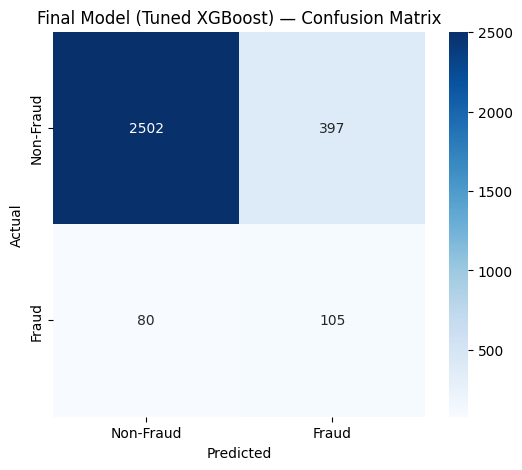

In [109]:
final_cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    final_cm,
    annot=True, fmt="d", cmap="Blues",
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Final Model ({FINAL_MODEL_NAME}) — Confusion Matrix")
plt.show()

In [110]:
# ── SHAP on FINAL_MODEL ──
final_preprocessor = FINAL_MODEL.named_steps["preprocessor"]
final_classifier   = FINAL_MODEL.named_steps["classifier"]
final_explainer    = shap.TreeExplainer(final_classifier)

X_test_final_transformed = final_preprocessor.transform(X_test)
final_shap_values        = final_explainer.shap_values(X_test_final_transformed)
final_feature_names      = final_preprocessor.get_feature_names_out()

print(f"SHAP computed on: {FINAL_MODEL_NAME}")
print(f"Features: {len(final_feature_names)}")

SHAP computed on: Tuned XGBoost
Features: 155


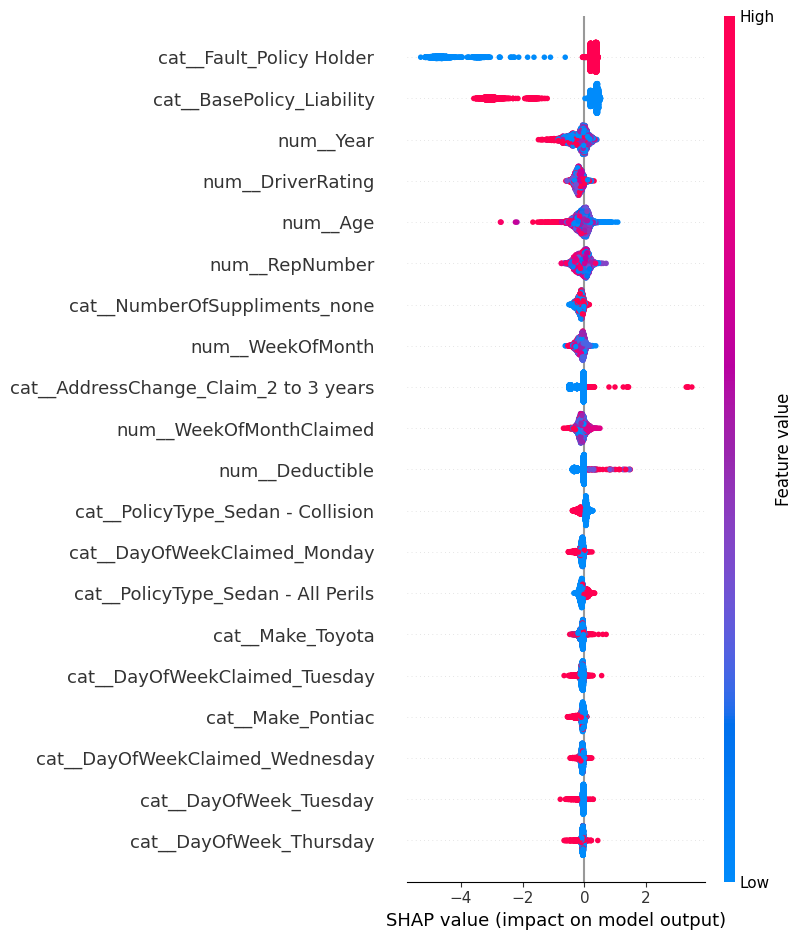

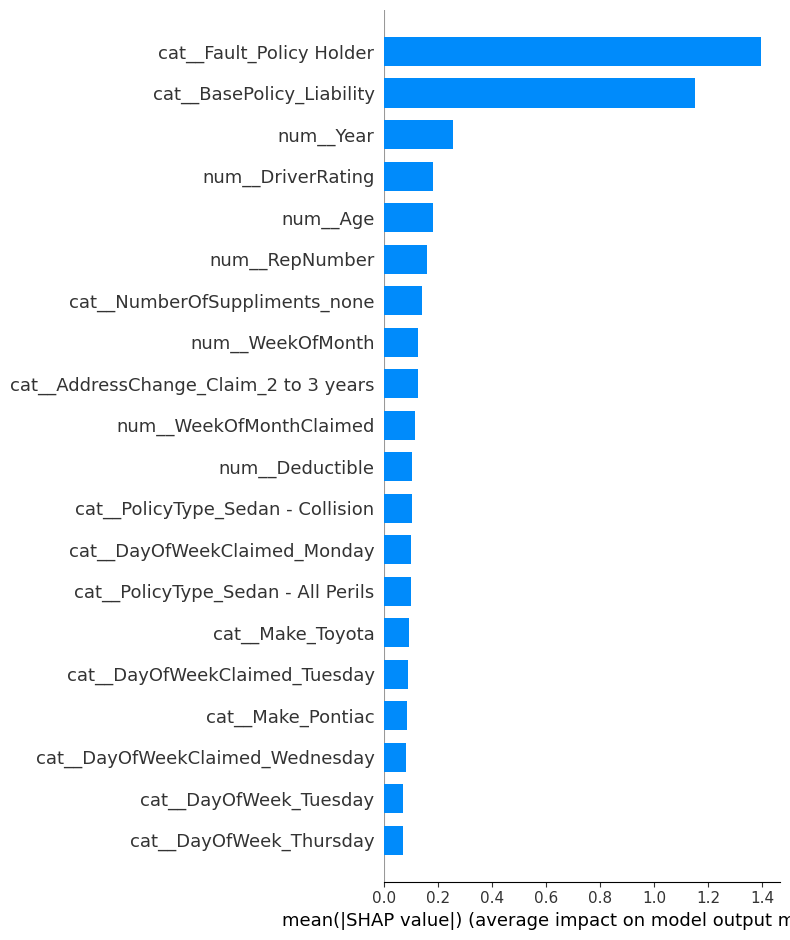

In [111]:
# Global SHAP summary
shap.summary_plot(
    final_shap_values,
    X_test_final_transformed,
    feature_names=final_feature_names
)

# Bar chart
shap.summary_plot(
    final_shap_values,
    X_test_final_transformed,
    feature_names=final_feature_names,
    plot_type="bar"
)

In [112]:
# ── COMPLETE ML REPORT ──
report_cols = [
    "Model", "PR-AUC", "ROC-AUC",
    "Precision", "Recall", "F1",
    "Recall@5%", "Recall@10%", "Recall@20%"
]

full_report = all_results_sorted[
    [c for c in report_cols if c in all_results_sorted.columns]
].reset_index(drop=True)

# Highlight best model
print("=" * 80)
print("  INSURANCE FRAUD DETECTION — FINAL ML REPORT")
print("=" * 80)
print(full_report.to_string(index=False))
print("=" * 80)
print(f"  SELECTED MODEL: {FINAL_MODEL_NAME}")
print(f"  Threshold     : {OPERATIONAL_THRESHOLD}")
print(f"  Model Version : {MODEL_VERSION}")
print("=" * 80)

# ── Top-K Fraud Detection Evaluation ──
print("\n── Top-K Fraud Detection Evaluation ──")
for k in [0.05, 0.10, 0.20]:
    r = recall_at_k(y_test, final_probabilities, k)
    p = precision_at_k(y_test, final_probabilities, k)
    n = int(len(final_probabilities) * k)
    print(f"  Top {int(k*100):2d}% ({n:4d} claims) → "
          f"Recall={r:.3f}  Precision={p:.3f}  "
          f"(captures {r*100:.1f}% of all actual fraud cases)")

# ── Final predict_claim_risk demo with FINAL_MODEL ──
print("\n── Live Prediction Demo (Final Model) ──")
example_claim_final = X_test.iloc[5].to_dict()
final_result = predict_claim_risk(
    example_claim_final,
    model=FINAL_MODEL,
    preprocessor=final_preprocessor,
    explainer=final_explainer,
    feature_names=final_feature_names,
    threshold=OPERATIONAL_THRESHOLD,
    model_version=MODEL_VERSION
)
print(f"Fraud Probability : {final_result['fraud_probability']*100:.2f}%")
print(f"Risk Level        : {final_result['risk_level']}")
print(f"Model Version     : {final_result['model_version']}")
print("\nTop Risk Factors:")
for f in final_result["top_risk_factors"]:
    print(f"  - {f['analyst_note']}")
print("\nProtective Factors:")
for f in final_result["top_protective_factors"]:
    print(f"  - {f['analyst_note']}")

  INSURANCE FRAUD DETECTION — FINAL ML REPORT
              Model  PR-AUC  ROC-AUC  Precision  Recall     F1  Recall@5%  Recall@10%  Recall@20%
      Tuned XGBoost  0.2774   0.8533     0.2092  0.5676 0.3057     0.2595      0.4054      0.6378
Logistic Regression  0.1502   0.7982     0.1301  0.8216 0.2247     0.1351      0.2378      0.5243
      Decision Tree  0.1705   0.7938     0.1483  0.3568 0.2095     0.1676      0.2757      0.4595
      Random Forest  0.1719   0.8063     0.1709  0.1838 0.1771     0.1730      0.2649      0.5351
            XGBoost  0.2531   0.8460     0.8750  0.0378 0.0725     0.2162      0.3892      0.6432
  Gradient Boosting  0.2035   0.8198     0.3182  0.0378 0.0676     0.1784      0.3027      0.5622
  SELECTED MODEL: Tuned XGBoost
  Threshold     : 0.1
  Model Version : 1.0.0

── Top-K Fraud Detection Evaluation ──
  Top  5% ( 154 claims) → Recall=0.259  Precision=0.312  (captures 25.9% of all actual fraud cases)
  Top 10% ( 308 claims) → Recall=0.405  Precision=